# 03. Inside one nowcast

Walk through every model at a single origin: the end-of-quarter nowcast for 2024Q2 (made with data
published by the end of June 2024), so each later backtest number has a concrete meaning.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from nowcast.config import HORIZON_LABELS

In [2]:
from nowcast.features import build_all, main_spec, feature_names, feature_groups, origin_month, training_mask
from nowcast.models import Standardiser, time_folds, all_models, _group_lasso_path, group_lambda_max
B = build_all([2])
q, h = pd.Period("2024Q2", "Q"), 2
T = origin_month(q, h)
names = [n for n in feature_names() if main_spec(n)]
X = B["X"][h][names]
mask = training_mask(X.index, B["gdp"], T)
tr = X.index[mask]
y = B["first"].reindex(tr).values
st = Standardiser().fit(X.loc[tr].values)
Z, z = st.transform(X.loc[tr].values), st.transform(X.loc[[q]].values)
groups = feature_groups()[[feature_names().index(n) for n in names]]
folds = time_folds(len(y))
print(f"origin {T}: {len(y)} training quarters ({tr[0]}-{tr[-1]}), {Z.shape[1]} features, {len(folds)} CV folds")

origin 2024-06: 99 training quarters (1998Q1-2024Q1), 236 features, 5 CV folds


In [3]:
rows = []
for m in all_models():
    m.fit(Z, y, folds, groups=groups, names=names)
    rows.append(dict(model=m.name, nowcast=float(m.predict(z)[0]),
                     non_zero=int((np.abs(m.coef_) > 1e-10).sum()),
                     penalty=getattr(m, "alpha_", np.nan)))
res = pd.DataFrame(rows).set_index("model")
print(f"ONS first estimate for {q}: {B['first'][q]:.2f}%")
res.round(3)

ONS first estimate for 2024Q2: 0.57%


,nowcast,non_zero,penalty
model,,,
Mean,0.367,0,NaN
AR,0.341,2,NaN
Bridge,0.219,8,NaN
OLS (all),0.163,236,NaN
Ridge,0.223,236,116.895
Lasso,0.140,34,0.027
Elastic net,0.185,42,0.092
Adaptive lasso,0.184,59,0.000
Group lasso,0.189,98,0.025


## Lasso path and cross-validation curve at this origin

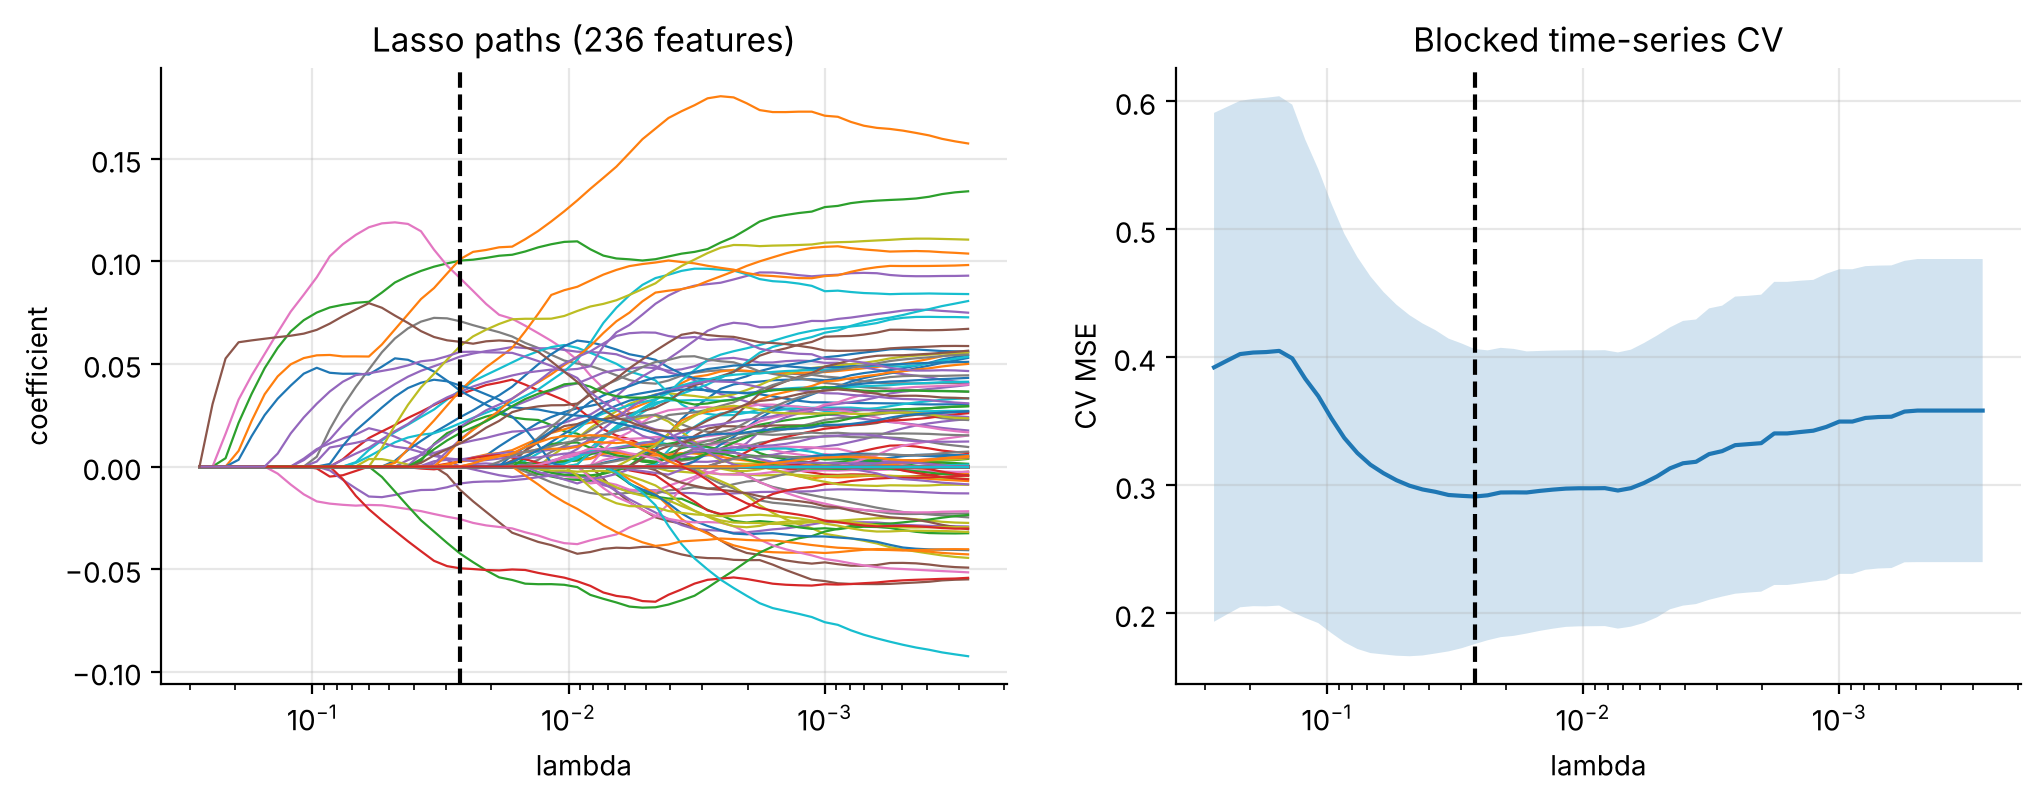

In [4]:
from sklearn.linear_model import LassoCV, lasso_path
m = LassoCV(cv=folds, alphas=60, max_iter=20000).fit(Z, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
alphas, coefs, _ = lasso_path(Z, y, alphas=m.alphas_)
ax[0].semilogx(alphas, coefs.T, lw=0.8); ax[0].axvline(m.alpha_, c="k", ls="--")
ax[0].invert_xaxis(); ax[0].set(xlabel="lambda", ylabel="coefficient", title="Lasso paths (236 features)")
mean, se = m.mse_path_.mean(1), m.mse_path_.std(1) / np.sqrt(m.mse_path_.shape[1])
ax[1].semilogx(m.alphas_, mean); ax[1].fill_between(m.alphas_, mean - se, mean + se, alpha=0.2)
ax[1].axvline(m.alpha_, c="k", ls="--"); ax[1].invert_xaxis()
ax[1].set(xlabel="lambda", ylabel="CV MSE", title="Blocked time-series CV");

The cross-validation curve is flat and noisy, with wide error bands from only five validation blocks.
That is typical with 31-107 quarterly observations, and it is one reason data-driven selection
struggles in this problem (see notebook 04).

## Group lasso: indicators enter as blocks of six lags

first indicators to enter as lambda falls: ['GDP_q1', 'IUMABEDR', 'GDP_q2', 'AP2Y', 'MGSX', 'RT_IOS', 'RT_IOM', 'RT_IOP']


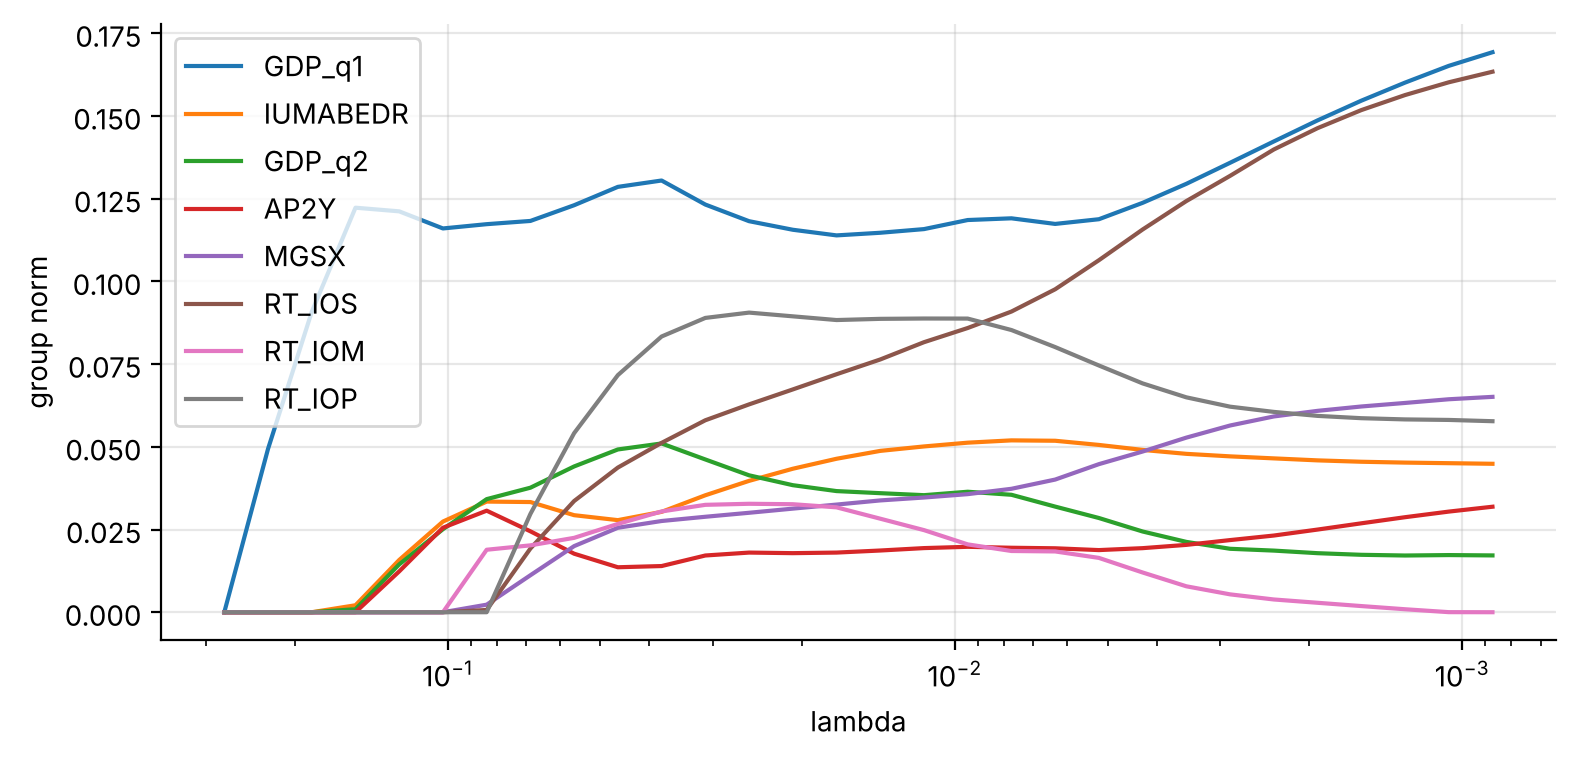

In [5]:
ym = y.mean(); zm = Z.mean(0)
lmax = group_lambda_max(Z, y - ym, groups)
lams = lmax * np.logspace(0, -2.5, 30)
path = _group_lasso_path(Z - zm, y - ym, groups, lams)
gnames = {g: n.rsplit("_l", 1)[0] for g, n in zip(groups, names)}
norms = pd.DataFrame([[np.linalg.norm(b[groups == g]) for g in np.unique(groups)] for b in path],
                     index=lams, columns=[gnames[g] for g in np.unique(groups)])
first_in = norms.gt(0).idxmax().where(norms.gt(0).any()).sort_values(ascending=False)
print("first indicators to enter as lambda falls:", list(first_in.index[:8]))
norms[first_in.index[:8]].plot(logx=True, figsize=(9, 4)).invert_xaxis()
plt.ylabel("group norm"); plt.xlabel("lambda");

## Bridge-anchored (partially penalised) models
The bridge equation uses the latest three months of real-time services and production output plus
two GDP lags. The anchored models leave those eight coefficients **unpenalised** and regularise only
the other indicators. By the Frisch-Waugh-Lovell theorem this equals residualising `y` and the other
indicators on the bridge regressors, then running the penalised model. `tests/test_models.py`
checks the equivalence against the direct solution.

In [6]:
from nowcast.models import BridgeAnchored, RidgeModel, SubsetOLS, BRIDGE_PREFIXES
br = SubsetOLS("Bridge", BRIDGE_PREFIXES).fit(Z, y, folds, names=names)
an = BridgeAnchored(RidgeModel()).fit(Z, y, folds, groups=groups, names=names)
core = [n for n in names if n.startswith(BRIDGE_PREFIXES)]
idx = [names.index(n) for n in core]
pd.DataFrame({"bridge OLS": br.coef_[idx], "bridge + ridge": an.coef_[idx]}, index=core).round(3)

,bridge OLS,bridge + ridge
RT_IOS_l0,0.059,0.059
RT_IOS_l1,0.041,0.040
RT_IOS_l2,0.154,0.154
RT_IOP_l0,0.224,0.223
RT_IOP_l1,0.146,0.146
RT_IOP_l2,0.023,0.024
GDP_q2,0.111,0.110
GDP_q1,0.133,0.135
